# Tutorial práctico: Suavizado Exponencial Triple (Holt-Winters)

Este tutorial está diseñado para que apliques un modelo Holt-Winters de forma **end-to-end**:

1. Entender cuándo usar versión aditiva o multiplicativa.
2. Ajustar modelos con `statsmodels`.
3. Realizar **selección de parámetros** con validación temporal.
4. Evaluar desempeño en un conjunto de prueba.
5. Diagnosticar residuos para validar supuestos.

> Base teórica: slides `S07-HoltWinters.html` (componentes nivel, tendencia, estacionalidad; estimación de $\alpha, \beta, \gamma$; validación con backtesting).

## 1) Setup e importación de librerías

Usaremos la serie clásica de pasajeros aéreos mensuales (`airline_passengers.csv`), que tiene estacionalidad anual ($m=12$).

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

## 2) Cargar datos y exploración rápida

Primero observamos la serie para inferir si la estacionalidad parece aditiva o multiplicativa.

In [2]:
df = pd.read_csv('airline_passengers.csv', parse_dates=['Month'])
df = df.rename(columns={'Month': 'fecha', 'Passengers': 'pasajeros'})
df = df.set_index('fecha').asfreq('MS')

serie = df['pasajeros']

display(df.head())
print(f'Observaciones: {len(serie)} | Inicio: {serie.index.min().date()} | Fin: {serie.index.max().date()}')

,pasajeros
fecha,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Observaciones: 144 | Inicio: 1949-01-01 | Fin: 1960-12-01


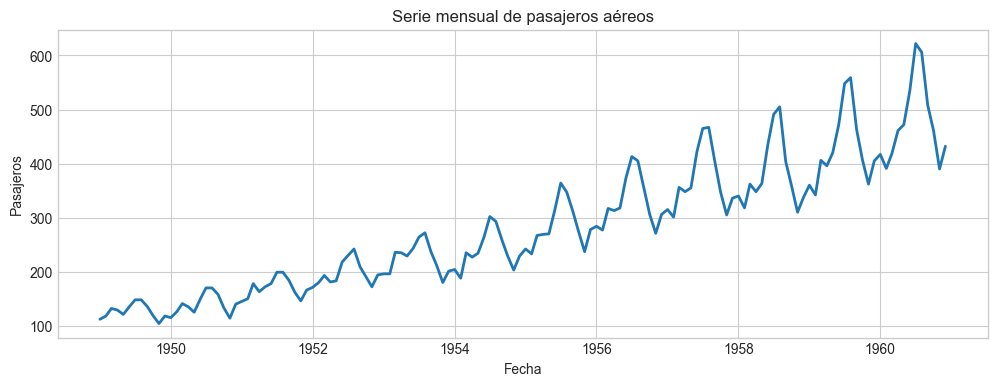

Amplitud estacional (1ra mitad): 67.50
Amplitud estacional (2da mitad): 173.50
La amplitud crece con el nivel: conviene probar estacionalidad multiplicativa.


In [3]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(serie, color='tab:blue', lw=2)
ax.set_title('Serie mensual de pasajeros aéreos')
ax.set_xlabel('Fecha')
ax.set_ylabel('Pasajeros')
plt.show()

# Regla visual simple: comparamos amplitud estacional en primera mitad vs segunda mitad.
first_half = serie.iloc[: len(serie)//2]
second_half = serie.iloc[len(serie)//2 :]

amp_first = first_half.groupby(first_half.index.month).mean().max() - first_half.groupby(first_half.index.month).mean().min()
amp_second = second_half.groupby(second_half.index.month).mean().max() - second_half.groupby(second_half.index.month).mean().min()

print(f'Amplitud estacional (1ra mitad): {amp_first:.2f}')
print(f'Amplitud estacional (2da mitad): {amp_second:.2f}')

if amp_second > amp_first * 1.25:
    print('La amplitud crece con el nivel: conviene probar estacionalidad multiplicativa.')
else:
    print('La amplitud se mantiene relativamente estable: conviene probar estacionalidad aditiva.')

## 3) Preparar particiones temporales (train/valid/test)

Para evitar fuga de información, dividimos respetando el orden temporal:

- **Train:** para ajustar parámetros del modelo.
- **Validación:** para seleccionar hiperparámetros ($\alpha, \beta, \gamma, \phi$ y tipo de estacionalidad).
- **Test:** evaluación final out-of-sample.

Train: 1949-01-01 -> 1956-12-01 | n=96
Valid: 1957-01-01 -> 1958-12-01 | n=24
Test : 1959-01-01 -> 1960-12-01 | n=24


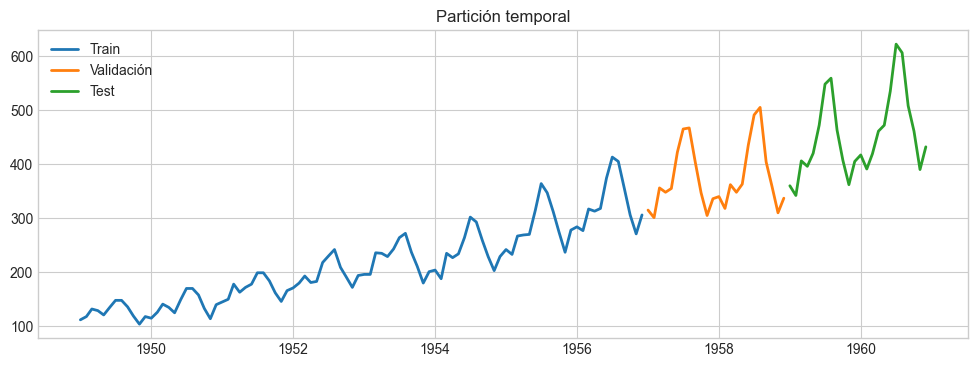

In [4]:
n_total = len(serie)
n_test = 24   # ultimos 24 meses
n_val = 24    # 24 meses previos para validacion

train = serie.iloc[: n_total - n_val - n_test]
valid = serie.iloc[n_total - n_val - n_test : n_total - n_test]
test = serie.iloc[n_total - n_test :]

print(f'Train: {train.index.min().date()} -> {train.index.max().date()} | n={len(train)}')
print(f'Valid: {valid.index.min().date()} -> {valid.index.max().date()} | n={len(valid)}')
print(f'Test : {test.index.min().date()} -> {test.index.max().date()} | n={len(test)}')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train, label='Train', lw=2)
ax.plot(valid, label='Validación', lw=2)
ax.plot(test, label='Test', lw=2)
ax.set_title('Partición temporal')
ax.legend()
plt.show()

## 4) Funciones auxiliares de métricas y ajuste

Usaremos MAE, RMSE y MAPE para comparar modelos.

In [5]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def mape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


def eval_metrics(y_true, y_pred):
    return {
        'MAE': mae(y_true, y_pred),
        'RMSE': rmse(y_true, y_pred),
        'MAPE_%': mape(y_true, y_pred),
    }


def fit_hw(train_series, seasonal, alpha, beta, gamma, damped, phi, m=12):
    model = ExponentialSmoothing(
        train_series,
        trend='add',
        damped_trend=damped,
        seasonal=seasonal,
        seasonal_periods=m,
        initialization_method='estimated',
    )

    fit = model.fit(
        optimized=False,
        smoothing_level=alpha,
        smoothing_trend=beta,
        smoothing_seasonal=gamma,
        damping_trend=phi if damped else None,
    )
    return fit

## 5) Selección de parámetros en validación

Probamos una grilla pequeña de hiperparámetros para que el proceso sea transparente:

- $\alpha, \beta, \gamma$ en valores discretos.
- Estacionalidad: `add` vs `mul`.
- Tendencia amortiguada: `True`/`False` con $\phi$ en una grilla.

Seleccionamos por **RMSE en validación**.

In [6]:
grid_alpha = [0.2, 0.4, 0.6, 0.8]
grid_beta = [0.1, 0.3, 0.5]
grid_gamma = [0.1, 0.3, 0.5]
grid_phi = [0.90, 0.95, 0.98]

results = []

for seasonal in ['add', 'mul']:
    for damped in [False, True]:
        phis = grid_phi if damped else [None]
        for alpha, beta, gamma, phi in product(grid_alpha, grid_beta, grid_gamma, phis):
            try:
                fit = fit_hw(
                    train_series=train,
                    seasonal=seasonal,
                    alpha=alpha,
                    beta=beta,
                    gamma=gamma,
                    damped=damped,
                    phi=phi,
                    m=12,
                )
                pred_val = fit.forecast(len(valid))
                score = eval_metrics(valid, pred_val)

                results.append({
                    'seasonal': seasonal,
                    'damped_trend': damped,
                    'alpha': alpha,
                    'beta': beta,
                    'gamma': gamma,
                    'phi': phi,
                    **score,
                })
            except Exception:
                continue

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)

print(f'Modelos evaluados: {len(results_df)}')
display(results_df.head(10))

Modelos evaluados: 288


,seasonal,damped_trend,alpha,beta,gamma,phi,MAE,RMSE,MAPE_%
0,mul,True,0.2,0.5,0.5,0.95,9.446431,11.964486,2.503613
1,mul,True,0.2,0.5,0.5,0.90,9.385669,12.820257,2.435166
2,mul,True,0.2,0.3,0.5,0.98,10.537583,13.869391,2.684699
3,mul,True,0.2,0.1,0.5,0.98,10.659173,14.353329,2.746580
4,mul,False,0.2,0.3,0.5,NaN,11.538208,14.425911,3.033868
5,mul,True,0.2,0.5,0.3,0.95,11.962818,15.998168,3.200915
6,mul,True,0.2,0.3,0.3,0.98,12.711107,16.403829,3.349329
7,mul,True,0.4,0.1,0.5,0.98,13.032951,16.867406,3.489681
8,mul,True,0.2,0.1,0.3,0.98,13.076523,16.946309,3.419509
9,mul,True,0.2,0.3,0.5,0.95,13.220688,17.448210,3.313952


Mejor configuración (por RMSE en validación):
{'seasonal': 'mul', 'damped_trend': True, 'alpha': 0.2, 'beta': 0.5, 'gamma': 0.5, 'phi': 0.95, 'MAE': 9.446430776877426, 'RMSE': 11.964486166102267, 'MAPE_%': 2.5036126374374104}


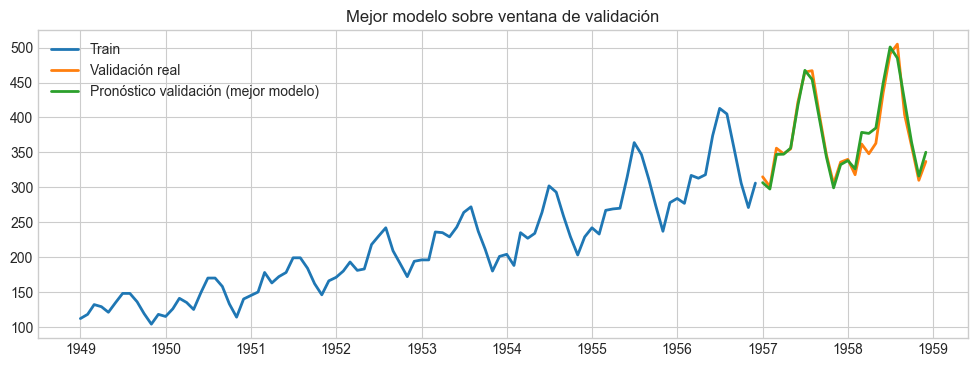

Métricas en validación (mejor modelo):
{'MAE': np.float64(9.446430776877426), 'RMSE': np.float64(11.964486166102267), 'MAPE_%': np.float64(2.5036126374374104)}


In [7]:
best = results_df.iloc[0].to_dict()
print('Mejor configuración (por RMSE en validación):')
print(best)

best_fit_train = fit_hw(
    train_series=train,
    seasonal=best['seasonal'],
    alpha=best['alpha'],
    beta=best['beta'],
    gamma=best['gamma'],
    damped=bool(best['damped_trend']),
    phi=best['phi'],
    m=12,
)

pred_val_best = best_fit_train.forecast(len(valid))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train, label='Train', lw=2)
ax.plot(valid, label='Validación real', lw=2)
ax.plot(pred_val_best.index, pred_val_best.values, label='Pronóstico validación (mejor modelo)', lw=2)
ax.set_title('Mejor modelo sobre ventana de validación')
ax.legend()
plt.show()

print('Métricas en validación (mejor modelo):')
print(eval_metrics(valid, pred_val_best))

## 6) Reentrenar con train+valid y evaluar en test

Con los hiperparámetros seleccionados, reentrenamos usando más datos (train+valid) y medimos desempeño final en test.

Métricas finales en TEST:
{'MAE': np.float64(42.239447784025636), 'RMSE': np.float64(47.48378968452938), 'MAPE_%': np.float64(9.210730066779039)}


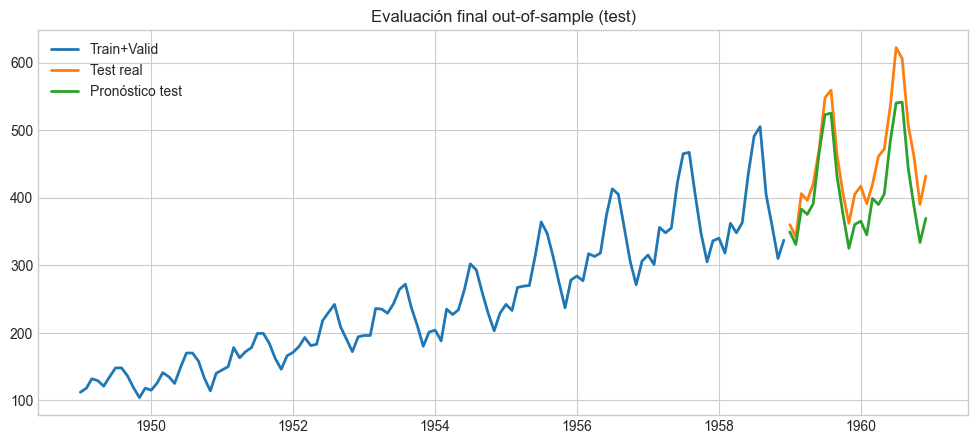

In [8]:
train_valid = pd.concat([train, valid])

final_fit = fit_hw(
    train_series=train_valid,
    seasonal=best['seasonal'],
    alpha=best['alpha'],
    beta=best['beta'],
    gamma=best['gamma'],
    damped=bool(best['damped_trend']),
    phi=best['phi'],
    m=12,
)

pred_test = final_fit.forecast(len(test))

test_metrics = eval_metrics(test, pred_test)
print('Métricas finales en TEST:')
print(test_metrics)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_valid, label='Train+Valid', lw=2)
ax.plot(test, label='Test real', lw=2)
ax.plot(pred_test.index, pred_test.values, label='Pronóstico test', lw=2)
ax.set_title('Evaluación final out-of-sample (test)')
ax.legend()
plt.show()

## 7) Diagnóstico de residuos

Siguiendo la teoría, un buen ajuste debería dejar residuos sin estructura clara (media cercana a 0 y baja autocorrelación).

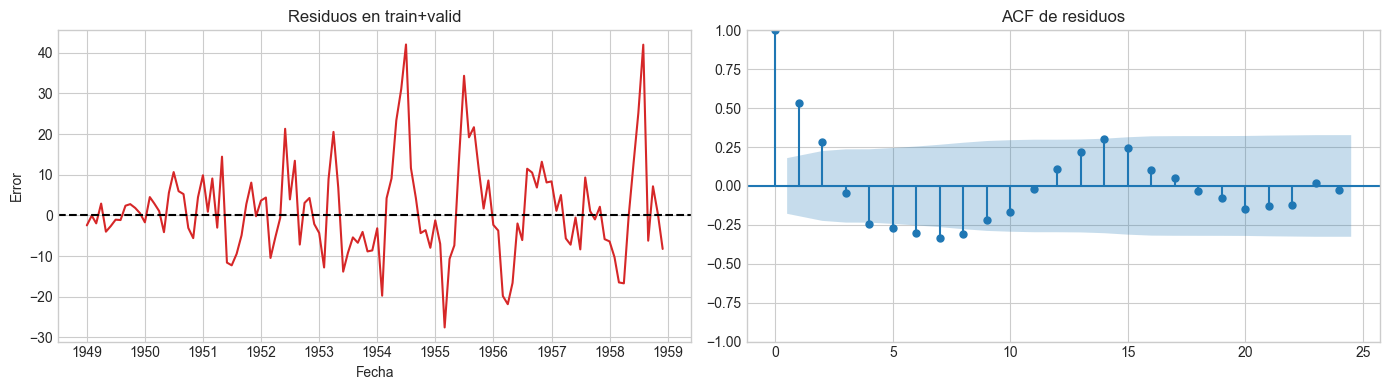

Media de residuos: 1.3437679945238281
Desviación estándar de residuos: 11.651143226899874

Prueba Ljung-Box (lag=12):


,lb_stat,lb_pvalue
12,113.267391,1.348504e-18


Hay evidencia de autocorrelación residual (p <= 0.05); considera un modelo más rico.


In [9]:
fitted_values = final_fit.fittedvalues
residuos = train_valid - fitted_values

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuos, color='tab:red')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Residuos en train+valid')
axes[0].set_xlabel('Fecha')
axes[0].set_ylabel('Error')

plot_acf(residuos.dropna(), lags=24, ax=axes[1])
axes[1].set_title('ACF de residuos')
plt.tight_layout()
plt.show()

print('Media de residuos:', residuos.mean())
print('Desviación estándar de residuos:', residuos.std())

lb = acorr_ljungbox(residuos.dropna(), lags=[12], return_df=True)
print('\nPrueba Ljung-Box (lag=12):')
display(lb)

if lb['lb_pvalue'].iloc[0] > 0.05:
    print('No hay evidencia fuerte de autocorrelación residual (p > 0.05).')
else:
    print('Hay evidencia de autocorrelación residual (p <= 0.05); considera un modelo más rico.')

## 8) Comparación rápida con ajuste automático de `statsmodels`

Además de la grilla manual (útil para aprender), probamos el ajuste optimizado automático para contrastar resultados.

,modelo,MAE,RMSE,MAPE_%
1,HW auto (optimized=True),36.515370,40.996785,8.012326
0,HW manual (grilla),42.239448,47.483790,9.210730


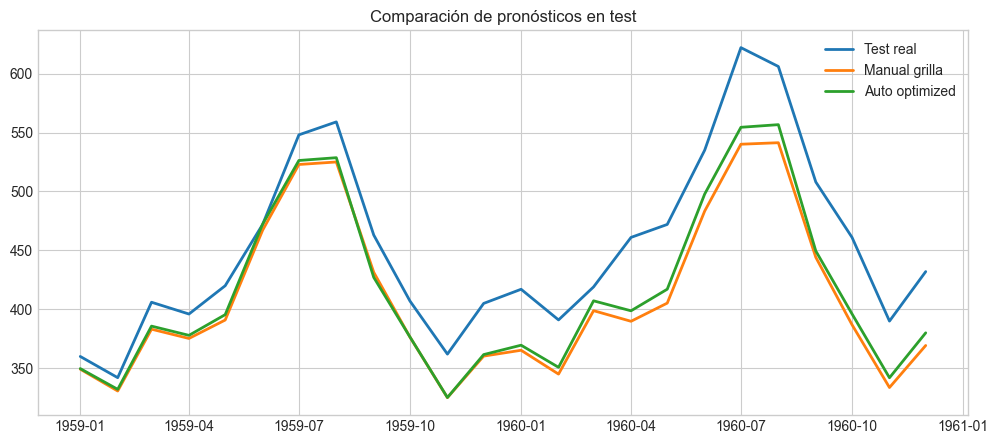

In [10]:
auto_model = ExponentialSmoothing(
    train_valid,
    trend='add',
    seasonal='mul',
    seasonal_periods=12,
    damped_trend=True,
    initialization_method='estimated',
)
auto_fit = auto_model.fit(optimized=True)
auto_pred_test = auto_fit.forecast(len(test))

auto_metrics = eval_metrics(test, auto_pred_test)
manual_metrics = eval_metrics(test, pred_test)

comparison = pd.DataFrame([
    {'modelo': 'HW manual (grilla)', **manual_metrics},
    {'modelo': 'HW auto (optimized=True)', **auto_metrics},
]).sort_values('RMSE')

display(comparison)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test, label='Test real', lw=2)
ax.plot(pred_test.index, pred_test.values, label='Manual grilla', lw=2)
ax.plot(auto_pred_test.index, auto_pred_test.values, label='Auto optimized', lw=2)
ax.set_title('Comparación de pronósticos en test')
ax.legend()
plt.show()

## 9) Actividades para estudiantes (entregable)

1. Cambia la grilla de búsqueda:
   - Prueba valores más finos para $\alpha, \beta, \gamma$.
   - Evalúa si mejora el RMSE en validación.
2. Compara tres escenarios:
   - `seasonal='add'`
   - `seasonal='mul'`
   - `seasonal='mul'` con `damped_trend=True`
3. Implementa una validación tipo rolling-origin:
   - Usa al menos 3 folds con horizonte de 12 meses.
   - Reporta MAE, RMSE y MAPE promedio.
4. Interpreta el diagnóstico de residuos:
   - ¿El modelo cumple razonablemente con residuos sin estructura?
   - Si no, ¿qué modelo alternativo propondrías (por ejemplo, SARIMA)?

## 10) Conclusión

Con este flujo aplicaste los puntos centrales de Holt-Winters vistos en clase:

- Descomposición implícita en nivel, tendencia y estacionalidad.
- Diferencia práctica entre formulación aditiva y multiplicativa.
- Selección de parámetros con validación temporal.
- Evaluación out-of-sample y diagnóstico de residuos.

Este pipeline sirve como baseline sólido para pronóstico estacional en problemas reales de ingeniería y negocio.